# Предлагане на труд: решения на задачите {#sec-labour-supply-problems}


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.grid": True, "grid.alpha": 0.3})

## Задача 2-3 {#sec-problem-2-3}

Том печели по \$15 на час за работа до 40 часа седмично. За всеки час над 40-ия му се заплаща по \$30 на час. Том е облаган с 20 процента данъчна ставка и плаща по \$4 на час за разходи за грижи за дете за всеки час, в който работи. Том получава по \$80 на седмица под формата на плащания за издръжка на дете. В седмицата има 110 часа (време, в което не се спи). Начертайте седмичната бюджетна линия на Том.

### Дефиниране на променливите

- Общо време: $T = 110$ (часа на седмица)
- Свободно време: $L$ (часове, в които не работи)
- Работно време: $H = 110 - L$
- Доход без работа: $V = 80$ (\$80 за издръжка за дете)
- Потребление: $C$ е общият седмичен доход, който Том може да похарчи

### Изчисляване на нетната часова ставка $w_{net}$

Трябва да превърнем брутната заплата в нетна, като извадим 20% данък и \$4 разход за детегледачка за всеки отработен час.

- За първите 40 часа ($H \le 40$): $w_1 = 15(1 - 0.20) - 4 = 8$ (\$8 на час)
- За часовете над 40 часа ($H > 40$): $w_2 = 30(1 - 0.20) - 4 = 20$ (\$20 на час)

### Определяне на ключовите точки на бюджетната линия

Бюджетната линия ще има чупка при 40 часа труд (което съответства на $110 - 40 = 70$ часа свободно време).

- Точка A – максимално свободно време: $L = 110$ и $H = 0$; $C = 80$ (доход само от издръжката на дете). Координати (110, 80).
- Точка B – чупка при 40 часа труд: $L = 70$ и $H = 40$; $C = 80 + 40 \cdot 8 = 400$. Координати (70, 400).
- Точка C – нулево свободно време: $L = 0$ и $H = 110$; първите 40 часа носят \$320, останалите 70 часа носят по \$20 на час: $C = 80 + 320 + 1400 = 1800$. Координати (0, 1800).

### Уравнения на сегментите

- Сегмент 1: $70 \le L \le 110$: $C = 80 + 8(110 - L) \implies C = 960 - 8L$
- Сегмент 2: $0 \le L < 70$: $C = 400 + 20(70 - L) \implies C = 1800 - 20L$

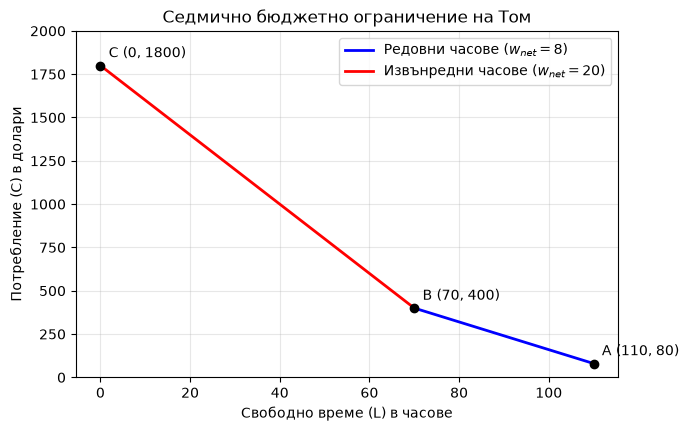

In [2]:
T, V = 110, 80
w1, w2, kink = 8, 20, 40

def budget_tom(L):
    H = T - L
    return V + w1 * np.minimum(H, kink) + w2 * np.maximum(H - kink, 0)

L1 = np.linspace(T - kink, T, 50)
L2 = np.linspace(0, T - kink, 50)

fig, ax = plt.subplots()
ax.plot(L1, budget_tom(L1), color="blue", lw=2, label=r"Редовни часове ($w_{net} = 8$)")
ax.plot(L2, budget_tom(L2), color="red", lw=2, label=r"Извънредни часове ($w_{net} = 20$)")
for name, l in zip("ABC", [110, 70, 0]):
    c = float(budget_tom(l))
    ax.plot(l, c, "ko")
    ax.annotate(f"{name} ({l}, {c:.0f})", (l, c), textcoords="offset points", xytext=(6, 6))
ax.set(xlabel="Свободно време (L) в часове", ylabel="Потребление (C) в долари",
       title="Седмично бюджетно ограничение на Том", ylim=(0, 2000))
ax.legend()
plt.show()

- Наклонът на бюджетната линия представлява нетната часова заплата.
- След 40-ия час работа (наляво от 70 часа свободно време) линията става по-стръмна, защото нетната заплата скача от \$8 на \$20.
- Точка A (\$80) показва дохода на Том, ако той избере изобщо да не работи, а само да почива.

**Възможни модификации**

- Как промяна в данъчната ставка би променила решението на Том за предлагане на труд?
- Как промяна в издръжката би променила това решение?
- Какво ще стане с предлагането на труд на Том, ако разходите за детегледачка станат фиксирана сума вместо почасов разход?

## Задача 2-4 {#sec-problem-2-4}

Синди извлича полезност от потреблението $C$ и свободното време (отдиха) $L$. Максималното свободно време, което тя може да консумира през всяка дадена седмица, е 110 часа. Нейната функция на полезност е $U(C, L) = C \cdot L$. Тази функционална форма предполага, че пределната норма на заместване (MRS) на Синди е $C/L$. Синди получава \$660 всяка седмица от своята прабаба – независимо от това колко работи. Каква е резервационната заплата на Синди?

### Дадено

- Максимално свободно време $L_{max} = 110$ часа на седмица
- Нетрудов доход $V = 660$ долара на седмица от прабабата
- Функция на полезност $U(C, L) = C \cdot L$
- Гранична норма на заместване $MRS = C/L$

### Решение

1. Определяне на координатите в точката на почивка. Ако Синди реши да не работи нито един час, нейните показатели ще бъдат: свободно време $L = 110$ и потребление $C = 660$.
2. Прилагане на формулата за резервационна заплата. Резервационната заплата се намира, като заместим стойностите от точката на почивка във формулата за $MRS$:

$$
w_{res} = MRS(L = 110, C = 660) = \frac{C}{L} = \frac{660}{110} = 6.
$$

Резервационната заплата на Синди е \$6 на час. Това означава, че тя ще се съгласи да започне работа само ако ѝ предложат заплащане, по-високо от \$6 на час. Ако заплатата е точно \$6, за нея ще бъде без значение дали работи или си почива.

Резервационна заплата: 6.0


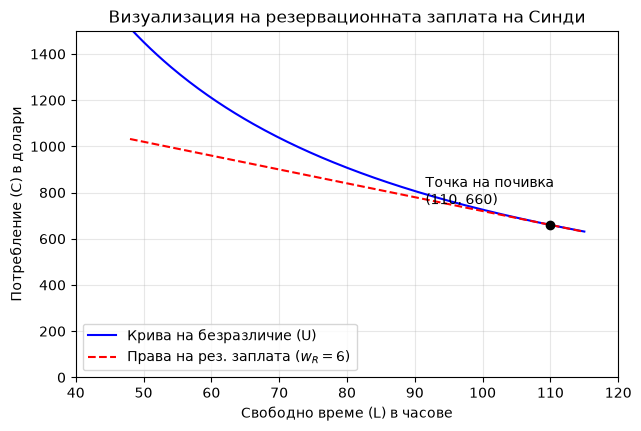

In [3]:
V, Lmax = 660, 110
u0 = V * Lmax
w_res = V / Lmax
print("Резервационна заплата:", w_res)

L = np.linspace(48, 115, 200)
fig, ax = plt.subplots()

ax.plot(L, u0 / L, color="blue", label="Крива на безразличие (U)")
ax.plot(L, V + w_res * (Lmax - L), "r--", label=rf"Права на рез. заплата ($w_R = {w_res:.0f}$)")
ax.plot(Lmax, V, "ko")
ax.annotate("Точка на почивка\n(110, 660)", (Lmax, V), textcoords="offset points", xytext=(-90, 15))
ax.set(xlim=(40, 120), ylim=(0, 1500), xlabel="Свободно време (L) в часове",
       ylabel="Потребление (C) в долари", title="Визуализация на резервационната заплата на Синди")
ax.legend(loc="lower left")
plt.show()

**Възможни модификации**

- Промяна в предпочитанията (тегла в полезността)
- Въвеждане на фиксирани разходи за труд
- Въвеждане на прогресивна данъчна ставка
- Ефект на дохода (промяна в получаваните пари от прабабата)

## Задача 2-6 {#sec-problem-2-6}

Предпочитанията на Шели по отношение на потреблението и свободното време могат да бъдат изразени чрез функцията:

$$
U(C, L) = (C - 100)(L - 40)
$$

Тази функция на полезност предполага, че пределната (маргиналната) полезност на свободното време за Шели е $C - 100$, а нейната пределна полезност на потреблението е $L - 40$.

В седмицата има 110 часа (време, в което не се спи), които тя може да разпредели между работа и свободно време. Шели печели по \$10 на час след облагане с данъци. Тя също така получава социални помощи в размер на \$320 всяка седмица, независимо от това колко работи.

Задачата разглежда поведението на индивида при избора между свободно време и потребление (моделът на индивидуалното предлагане на труд).

### Дадено

- Функция на полезност: $U(C, L) = (C - 100)(L - 40)$
- Пределна полезност: $MU_L = C - 100$ и $MU_C = L - 40$
- Общо разполагаемо време: $T = 110$ часа на седмица
- Нетна заплата: $w = 10$ долара на час
- Нетрудов доход: $V = 320$ долара на седмица от социални помощи

### Начертайте бюджетната линия на Шели

Бюджетното ограничение се определя от уравнението $C = V + w(T - L)$. Заместваме стойностите от задачата:

$$
C = 320 + 10(110 - L) = 1420 - 10L, \quad 0 \le L \le 110.
$$

- Точка на почивка (endowment point): ако Шели не работи, $L = 110$ и $C = 320$. Координати (110, 320).
- Точка на пълна заетост: ако Шели работи през цялото време, $L = 0$ и $C = 1420$. Координати (0, 1420).

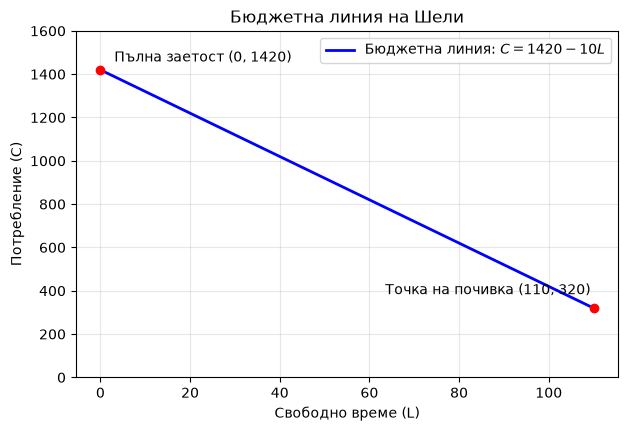

In [4]:
T, V, w = 110, 320, 10
L = np.linspace(0, T, 100)

fig, ax = plt.subplots()
ax.plot(L, V + w * (T - L), color="blue", lw=2, label=r"Бюджетна линия: $C = 1420 - 10L$")
ax.plot([0, 110], [1420, 320], "ro")
ax.annotate("Пълна заетост (0, 1420)", (0, 1420), textcoords="offset points", xytext=(10, 6))
ax.annotate("Точка на почивка (110, 320)", (110, 320), textcoords="offset points", xytext=(-150, 10))
ax.set(xlabel="Свободно време (L)", ylabel="Потребление (C)", title="Бюджетна линия на Шели", ylim=(0, 1600))
ax.legend()
plt.show()

### Каква е пределната степен на замяна (MRS) на Шели, когато $L = 100$ и тя се намира върху своята бюджетна линия?

Маргиналната степен на замяна (MRS) ни казва колко потребление Шели е готова да жертва за един допълнителен час свободно време:

$$
MRS = \frac{MU_L}{MU_C} = \frac{C - 100}{L - 40}.
$$

Първо трябва да намерим колко е потреблението $C$, когато тя е на бюджетната линия при $L = 100$: $C = 320 + 10 \cdot (110 - 100) = 420$. Тогава

$$
MRS = \frac{420 - 100}{100 - 40} = \frac{320}{60} \approx 5.3.
$$

### Каква е резервационната работна заплата на Шели?

Резервационната заплата $w_{res}$ е минималната заплата, при която Шели би се съгласила да започне работа. Тя се изчислява като $MRS$ в точката, където Шели изобщо не работи ($L = 110$, $C = 320$):

$$
w_{res} = MRS(110, 320) = \frac{320 - 100}{110 - 40} = \frac{220}{70} \approx 3.14.
$$

Тъй като пазарната заплата $w = 10$ е по-висока от резервационната, Шели ще предпочете да работи.

### Намерете оптималното количество потребление и свободно време за Шели

За оптималния избор трябва да бъде изпълнено условието за допирателна:

$$
MRS = \frac{MU_L}{MU_C} = w \implies \frac{C - 100}{L - 40} = 10 \implies C - 100 = 10(L - 40) \implies C = 10L - 300.
$$

Заместваме това потребление в уравнението на бюджетното ограничение:

$$
10L - 300 = 1420 - 10L \implies 20L = 1720 \implies L = 86 \text{ часа свободно време.}
$$

Потреблението е $C = 1420 - 10 \cdot 86 = 560$ долара, а часовете труд са $H = 110 - 86 = 24$ часа работа. Шели ще работи 24 часа, ще разполага с 86 часа свободно време и ще консумира стоки на стойност \$560.

In [5]:
MRS = lambda C, L: (C - 100) / (L - 40)
budget = lambda L: 320 + 10 * (110 - L)

print("MRS при L=100:", MRS(budget(100), 100))
print("Резервационна заплата:", MRS(320, 110))

L = np.linspace(40.01, 110, 200_001)
C = budget(L)
U = (C - 100) * (L - 40)
i = U.argmax()
print(f"Оптимум: L* = {L[i]:.2f}, C* = {C[i]:.2f}, H* = {110 - L[i]:.2f}")

MRS при L=100: 5.333333333333333
Резервационна заплата: 3.142857142857143
Оптимум: L* = 86.00, C* = 560.00, H* = 24.00


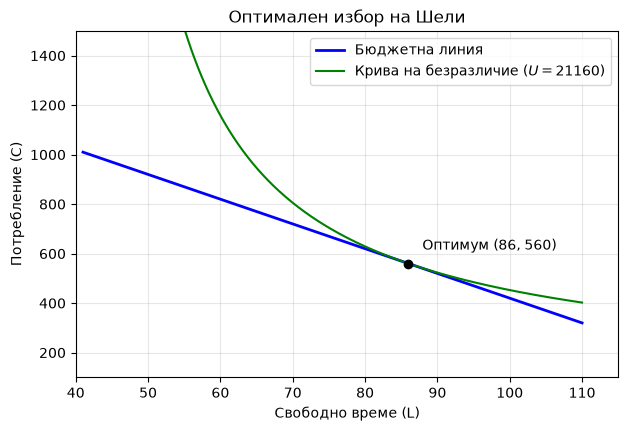

In [6]:
L = np.linspace(41, 110, 300)
Ls, Cs = 86, 560
Us = (Cs - 100) * (Ls - 40)

fig, ax = plt.subplots()
ax.plot(L, 320 + 10 * (110 - L), color="blue", lw=2, label="Бюджетна линия")
ax.plot(L, 100 + Us / (L - 40), "g", label=f"Крива на безразличие ($U = {Us}$)")
ax.plot(Ls, Cs, "ko")
ax.annotate("Оптимум (86, 560)", (Ls, Cs), textcoords="offset points", xytext=(10, 10))
ax.set(xlim=(40, 115), ylim=(100, 1500), xlabel="Свободно време (L)", ylabel="Потребление (C)",
       title="Оптимален избор на Шели")
ax.legend()
plt.show()

**Възможни модификации**

- Промяна в бюджетното ограничение (външни фактори)
- Промяна в предпочитанията (функцията на полезност)
- Анализ на ефектите (икономически въпроси)

## Задача 2-8 {#sec-problem-2-8}

Temporary Assistance for Needy Families (TANF) е федерална програма за социални помощи, която предоставя финансова помощ на семейства с ниски доходи, които имат деца. Програмата TANF има за цел да помогне на семействата да постигнат самостоятелност чрез работа.

- През 1999 г. 4860 получатели на помощи по програмата TANF са били попитани колко часа са работили през предходната седмица.
- През 2000 г. 4392 от тези получатели отново са били обект на същите правила на TANF и отново са били попитани за отработените им часове през предходната седмица.
- Останалите 468 лица са били разпределени на случаен принцип към експеримент с т.нар. „негативен подоходен данък“ (NIT), който предоставя финансови стимули за работа на получателите на социални помощи и ги подчинява на своите правила. Подобно на другата група, те също са били попитани за работните им часове през предходната седмица. Данните от експеримента се съдържат в таблицата по-долу.

In [7]:
data = pd.DataFrame(
    {
        "Брой": [4392, 468],
        "Работили 1999": [1217, 131],
        "Работили 2000": [1568, 213],
        "Часове 1999": [15578, 1638],
        "Часове 2000": [20698, 2535],
    },
    index=["TANF", "NIT"],
)
data.loc["Общо"] = data.sum()
data

,Брой,Работили 1999,Работили 2000,Часове 1999,Часове 2000
TANF,4392,1217,1568,15578,20698
NIT,468,131,213,1638,2535
Общо,4860,1348,1781,17216,23233


### Какъв ефект е имал експериментът с NIT върху коефициента на заетост на получателите на обществена помощ?

За да намерим ефекта, първо трябва да изчислим процента на заетост (заети лица / общ брой лица) за всяка група и всяка година.

In [8]:
d = data.loc[["TANF", "NIT"]]
emp = pd.DataFrame({
    "1999 г. (преди)": d["Работили 1999"] / d["Брой"] * 100,
    "2000 г. (след)": d["Работили 2000"] / d["Брой"] * 100,
})
emp["Разлика във времето (Δ)"] = emp["2000 г. (след)"] - emp["1999 г. (преди)"]
emp = emp.loc[["NIT", "TANF"]]
emp.index = ["NIT (Третирана)", "TANF (Контролна)"]
emp.loc["DiD ефект"] = [np.nan, np.nan, emp.iloc[0, 2] - emp.iloc[1, 2]]
emp.round(2)

,1999 г. (преди),2000 г. (след),Разлика във времето (Δ)
NIT (Третирана),27.99,45.51,17.52
TANF (Контролна),27.71,35.70,7.99
DiD ефект,NaN,NaN,9.53


Изводът е, че експериментът с негативния подоходен данък е увеличил коефициента на заетост сред получателите на помощи с 9.52 процентни пункта.

### Какъв ефект е имал експериментът с NIT върху седмичните отработени часове на тези получатели на обществена помощ, които са имали положителен брой работни часове през седмицата на проучването?

Тук трябва да внимаваме: условието изисква да анализираме само хората, които реално са работили (positive hours). За целта делим общите часове на броя на хората, които са работили.

In [9]:
hrs = pd.DataFrame({
    "1999 г. (преди)": d["Часове 1999"] / d["Работили 1999"],
    "2000 г. (след)": d["Часове 2000"] / d["Работили 2000"],
})
hrs["Разлика във времето (Δ)"] = hrs["2000 г. (след)"] - hrs["1999 г. (преди)"]
hrs = hrs.loc[["NIT", "TANF"]]
hrs.index = ["NIT (Третирана)", "TANF (Контролна)"]
hrs.loc["DiD ефект"] = [np.nan, np.nan, hrs.iloc[0, 2] - hrs.iloc[1, 2]]
hrs.round(1)

,1999 г. (преди),2000 г. (след),Разлика във времето (Δ)
NIT (Третирана),12.5,11.9,-0.6
TANF (Контролна),12.8,13.2,0.4
DiD ефект,NaN,NaN,-1.0


Извод: въпреки че повече хора са започнали работа (резултата от предната част на задачата), тези, които вече работят, са намалили средното си работно време с 1 час седмично в сравнение с контролната група.

### Икономическа интерпретация на резултатите

Този резултат е класически пример за двата ефекта при въвеждането на субсидия или данъчно облекчение.

- На входа на пазара (extensive margin): NIT е мотивирал повече хора да започнат работа. Положителният ефект е 9.52 пр.п.
- Интензивност на труда (intensive margin): веднъж намерили работа, хората работят малко по-малко. Негативният ефект е 1 час по-малко. Това вероятно се дължи на ефекта на дохода (вече са по-богати благодарение на трансфера и могат да си „купят“ повече свободно време) или на високата пределна данъчна ставка при фазата на постепенно спиране на помощта.

**Възможни модификации**

- Друг пример, в който да приложите метода „разлика в разликите“.
- За целта условието ясно ще посочва, че работите с третирана/експериментална група и контролна група от лица.

## Задача 2-14 {#sec-problem-2-14}

Разгледайте случай на човек, който може да работи до 80 часа на седмица при брутна заплата от \$20 на час, но плаща постоянен данък върху възнаграждението в размер на 20%. При тези условия работникът максимизира своята полезност, като избира да работи 50 часа седмично. Правителството предлага въвеждането на отрицателен подоходен данък, при който всеки получава по \$300 на седмица (трансфер), като всеки може да допълва дохода си чрез работа. За да се финансира този отрицателен подоходен данък, данъкът върху възнагражденията се увеличава на 50%.

### Дадено

- Първоначална ситуация (базов сценарий):
    - Общо време $T = 80$ часа
    - Нетна заплата $w_1 = 20 \cdot (1 - 0.2) = 16$ долара на час
    - Нетрудов доход $V_1 = 0$
    - Избор: 50 часа работа $\implies L = 30$, $C = 50 \cdot 16 = 800$ долара
- Нова ситуация (отрицателен подоходен данък, NIT):
    - Нетна заплата $w_2 = 20 \cdot (1 - 0.5) = 10$ долара на час
    - Нетрудов доход $V_2 = 300$ долара гарантиран доход
    - Бюджетно уравнение: $C = 300 + 10 \cdot (80 - L)$

### На една графика начертайте първоначалното бюджетно ограничение на работника и бюджетното му ограничение при системата с отрицателен подоходен данък

За да начертаем графика с бюджетните прави, ни трябват крайните точки.

- Правата, съответстваща на базовия сценарий, е от ($L = 80$, $C = 0$) до ($L = 0$, $C = 1280$).
- Правата, съответстваща на новия NIT сценарий, е от ($L = 80$, $C = 300$) до ($L = 0$, $C = 1100$).

Трябва ни точката на пресичане на двете прави. За да намерим къде се пресичат двете бюджетни прави, приравняваме доходите в двата случая:

- Доход при базовия сценарий: $C = 16 \cdot h$ заплащане на час по отработените часове $h$
- Доход при новия сценарий: $C = 300 + 10 \cdot h$
- Следователно решаваме $16 \cdot h = 300 + 10 \cdot h$ и получаваме, че $h = 50$.

Двете линии се пресичат точно в точката на първоначалния избор ($L = 30$, $C = 800$).

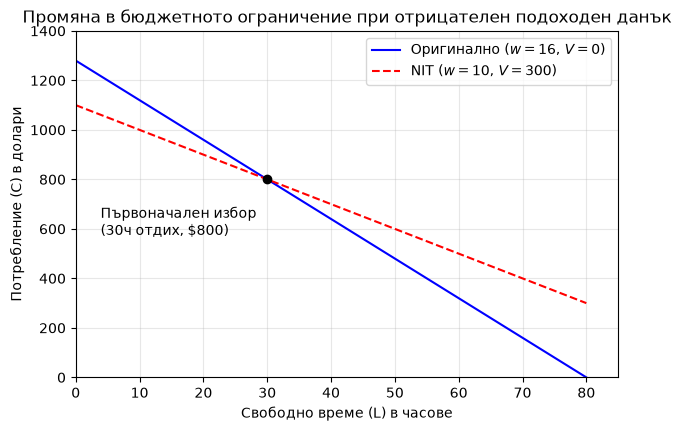

Пресичане при h = 50.0 -> L = 30.0 , C = 800.0


In [10]:
T = 80
L = np.linspace(0, T, 100)

fig, ax = plt.subplots()
ax.plot(L, 16 * (T - L), color="blue", label="Оригинално ($w = 16$, $V = 0$)")
ax.plot(L, 300 + 10 * (T - L), "r--", label="NIT ($w = 10$, $V = 300$)")
ax.plot(30, 800, "ko")
ax.annotate("Първоначален избор\n(30ч отдих, \\$800)", (30, 800), textcoords="offset points", xytext=(-120, -40))
ax.set(xlim=(0, 85), ylim=(0, 1400), xlabel="Свободно време (L) в часове", ylabel="Потребление (C) в долари",
       title="Промяна в бюджетното ограничение при отрицателен подоходен данък")
ax.legend()
plt.show()

h = 300 / (16 - 10)
print("Пресичане при h =", h, "-> L =", T - h, ", C =", 16 * h)

### Покажете, че работникът ще избере да работи по-малко часове, ако се приеме отрицателният подоходен данък

В точката на първоначалния избор $L = 30$ пределната норма на заместване е $MRS = $ нетната заплата $w_1 = 16$.

При новия сценарий:

- Ефект на заместването: нетната заплата пада от \$16 на \$10. Свободното време става „по-евтино“ (алтернативният му разход намалява), което го стимулира да консумира повече свободно време и да работи по-малко.
- Ефект на дохода: тъй като новата бюджетна линия минава през старата оптимална точка, работникът може да запази същото потребление. Въпреки това, за всяка точка вдясно от $L = 30$ (повече отдих), новата бюджетна линия е над старата.

Тъй като в точката ($L = 30$, $C = 800$) работникът има $MRS = 16$, а новата пазарна цена на свободното време е само $w_2 = 10$, той оценява допълнителния час почивка повече, отколкото пазарът му плаща, за да работи. Следователно той ще се премести надясно по бюджетната линия – повече свободно време и по-малко работни часове ($h < 50$).

### Ще бъде ли полезността на работника по-висока при системата с отрицателен подоходен данък?

Да, полезността ще бъде по-висока.

- Първоначалният избор ($L = 30$, $C = 800$) все още е достъпен за работника.
- Новата бюджетна линия обаче му позволява да избере комбинации от свободно време и потребление, които преди са били недостъпни (цялата зона вдясно от точката на пресичане, където новата линия е по-висока от старата).
- Тъй като той оптимизира избора си и се премества към точка с по-високо ниво на свободно време, която лежи над старата крива на безразличие, той достига по-високо ниво на полезност.

**Възможни модификации**

- Промяна в часовите ставки, данъчната ставка, трансфера, максималния брой часове за труд
- Добавяне на фиксиран разход от работа (transport/childcare)
- Вкарване в условието на заплащане за извънреден труд
- Сравнение на двама работници с различни предпочитания при една и съща политика (напр. коя политика е по-вероятно да намали труда: трансфер + по-висок данък срещу само трансфер)